In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [2]:
PATH = "weather.csv"  

df = pd.read_csv(PATH)

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = df.sort_values("date").reset_index(drop=True)

target_cols = ["T (degC)", "p (mbar)", "rh (%)"]

data = df[["date"] + target_cols].copy()

n = len(data)
split_idx = int(n * 0.8)

train_raw = data.iloc[:split_idx].copy()
test_raw  = data.iloc[split_idx:].copy()

print("Total rows:", n)
print("Train rows:", len(train_raw), "Test rows:", len(test_raw))
print("Train date range:", train_raw["date"].iloc[0], "->", train_raw["date"].iloc[-1])
print("Test  date range:", test_raw["date"].iloc[0],  "->", test_raw["date"].iloc[-1])


Total rows: 52696
Train rows: 42156 Test rows: 10540
Train date range: 2020-01-01 00:10:00 -> 2020-10-19 19:20:00
Test  date range: 2020-10-19 19:30:00 -> 2021-01-01 00:00:00


In [3]:
scaler = MinMaxScaler()
scaler.fit(train_raw[target_cols])

all_scaled = scaler.transform(data[target_cols])
all_scaled_df = pd.DataFrame(all_scaled, columns=target_cols)


## Make Time Windows

In [8]:
def make_windows_all(scaled_df: pd.DataFrame, split_idx: int,
                     feature_cols: list[str], target_col: str,
                     window_size: int):
   
    X_list, y_list, t_index_list = [], [], []
    Xv = scaled_df[feature_cols].values
    yv = scaled_df[target_col].values

    for i in range(window_size, len(scaled_df)):
        X_list.append(Xv[i-window_size:i])
        y_list.append(yv[i])
        t_index_list.append(i)

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.float32)
    t_index = np.array(t_index_list, dtype=np.int64)

    train_mask = t_index < split_idx
    test_mask  = t_index >= split_idx

    X_train, y_train = X[train_mask], y[train_mask]
    X_test,  y_test  = X[test_mask],  y[test_mask]
    t_test_index = t_index[test_mask]  # align to dates later

    return X_train, y_train, X_test, y_test, t_test_index


def inverse_scale_target(scaled_values_1d: np.ndarray, target_col: str) -> np.ndarray:
   
    idx = target_cols.index(target_col)
    dummy = np.zeros((len(scaled_values_1d), len(target_cols)), dtype=np.float32)
    dummy[:, idx] = scaled_values_1d.reshape(-1)
    inv = scaler.inverse_transform(dummy)
    return inv[:, idx]


## Building models (LSTM, GRU, CNN1D)

In [11]:
def build_lstm(input_shape):
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.LSTM(64),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


def build_gru(input_shape):
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.GRU(64),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


def build_cnn1d(input_shape):
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(filters=64, kernel_size=3, activation="relu", padding="causal"),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(filters=64, kernel_size=3, activation="relu", padding="causal"),
        layers.GlobalAveragePooling1D(),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


## Metrics Function

In [14]:
def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}


def plot_actual_vs_pred(dates, y_true, y_pred, title):
    plt.figure()
    plt.plot(dates, y_true, label="Actual")
    plt.plot(dates, y_pred, label="Predicted")
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()


## Train Models


Target=T (degC) | window=10 | Xtr=(42146, 10, 1) Xte=(10540, 10, 1)
LSTM -> MAE=0.1757 | RMSE=0.2491 | R2=0.9975
GRU -> MAE=0.1623 | RMSE=0.2317 | R2=0.9978
CNN1D -> MAE=0.3523 | RMSE=0.4767 | R2=0.9909

Target=T (degC) | window=20 | Xtr=(42136, 20, 1) Xte=(10540, 20, 1)
LSTM -> MAE=0.2464 | RMSE=0.3527 | R2=0.9950


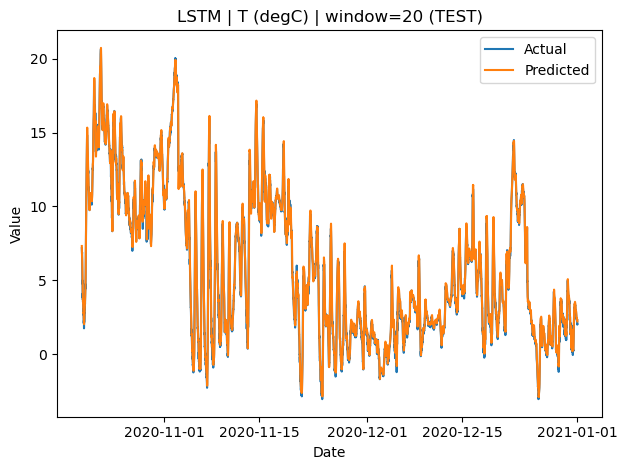

GRU -> MAE=0.1213 | RMSE=0.1813 | R2=0.9987
CNN1D -> MAE=0.5501 | RMSE=0.7872 | R2=0.9751

Target=T (degC) | window=30 | Xtr=(42126, 30, 1) Xte=(10540, 30, 1)
LSTM -> MAE=0.2834 | RMSE=0.3931 | R2=0.9938
GRU -> MAE=0.1627 | RMSE=0.2424 | R2=0.9976
CNN1D -> MAE=0.6029 | RMSE=0.8319 | R2=0.9722

Target=p (mbar) | window=10 | Xtr=(42146, 10, 1) Xte=(10540, 10, 1)
LSTM -> MAE=0.0998 | RMSE=0.1612 | R2=0.9998
GRU -> MAE=0.0863 | RMSE=0.1334 | R2=0.9998
CNN1D -> MAE=0.4822 | RMSE=0.9854 | R2=0.9916

Target=p (mbar) | window=20 | Xtr=(42136, 20, 1) Xte=(10540, 20, 1)
LSTM -> MAE=0.3608 | RMSE=0.5686 | R2=0.9972
GRU -> MAE=0.2452 | RMSE=0.3228 | R2=0.9991
CNN1D -> MAE=0.7082 | RMSE=1.1395 | R2=0.9888

Target=p (mbar) | window=30 | Xtr=(42126, 30, 1) Xte=(10540, 30, 1)
LSTM -> MAE=0.2965 | RMSE=0.3936 | R2=0.9987
GRU -> MAE=0.1574 | RMSE=0.2108 | R2=0.9996
CNN1D -> MAE=0.9298 | RMSE=1.3119 | R2=0.9852

Target=rh (%) | window=10 | Xtr=(42146, 10, 1) Xte=(10540, 10, 1)
LSTM -> MAE=1.0061 | RMSE=1

In [17]:
WINDOW_SIZES = [10, 20, 30]
EPOCHS = 30
BATCH_SIZE = 64

targets_to_run = ["T (degC)", "p (mbar)", "rh (%)"]

builders = {
    "LSTM": build_lstm,
    "GRU": build_gru,
    "CNN1D": build_cnn1d
}

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
]

results = []

for target_col in targets_to_run:
    feature_cols_uni = [target_col]

    for w in WINDOW_SIZES:
        Xtr, ytr, Xte, yte, t_te_idx = make_windows_all(
            scaled_df=all_scaled_df,
            split_idx=split_idx,
            feature_cols=feature_cols_uni,
            target_col=target_col,
            window_size=w
        )

        input_shape = (Xtr.shape[1], Xtr.shape[2])
        print(f"\nTarget={target_col} | window={w} | Xtr={Xtr.shape} Xte={Xte.shape}")

        for model_name, build_fn in builders.items():
            model = build_fn(input_shape)

            model.fit(
                Xtr, ytr,
                validation_split=0.1,
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                callbacks=callbacks,
                verbose=0
            )

            yhat_scaled = model.predict(Xte, verbose=0).reshape(-1)

            y_true = inverse_scale_target(yte, target_col)
            y_pred = inverse_scale_target(yhat_scaled, target_col)

            metrics = evaluate_regression(y_true, y_pred)
            results.append({
                "target": target_col,
                "mode": "univariate",
                "window": w,
                "model": model_name,
                **metrics
            })

            print(f"{model_name} -> MAE={metrics['MAE']:.4f} | RMSE={metrics['RMSE']:.4f} | R2={metrics['R2']:.4f}")

            if target_col == "T (degC)" and w == 20 and model_name == "LSTM":
                dates_test = data["date"].iloc[t_te_idx].values
                plot_actual_vs_pred(dates_test, y_true, y_pred, f"{model_name} | {target_col} | window={w} (TEST)")


In [19]:
results_df = pd.DataFrame(results).sort_values(["target", "window", "model"]).reset_index(drop=True)
results_df


,target,mode,window,model,MAE,MSE,RMSE,R2
0,T (degC),univariate,10,CNN1D,0.352336,0.227262,0.476720,0.990865
1,T (degC),univariate,10,GRU,0.162311,0.053683,0.231695,0.997842
2,T (degC),univariate,10,LSTM,0.175651,0.062042,0.249083,0.997506
3,T (degC),univariate,20,CNN1D,0.550148,0.619721,0.787224,0.975089
4,T (degC),univariate,20,GRU,0.121299,0.032866,0.181289,0.998679
5,T (degC),univariate,20,LSTM,0.246439,0.124429,0.352745,0.994998
6,T (degC),univariate,30,CNN1D,0.602881,0.692027,0.831881,0.972182
7,T (degC),univariate,30,GRU,0.162736,0.058763,0.242412,0.997638
8,T (degC),univariate,30,LSTM,0.283372,0.154537,0.393112,0.993788
9,p (mbar),univariate,10,CNN1D,0.482199,0.970993,0.985390,0.991624


In [21]:
best_per_target = (
    results_df.sort_values(["target", "RMSE"])
              .groupby("target")
              .head(1)
              .reset_index(drop=True)
)

best_per_target


,target,mode,window,model,MAE,MSE,RMSE,R2
0,T (degC),univariate,20,GRU,0.121299,0.032866,0.181289,0.998679
1,p (mbar),univariate,10,GRU,0.086271,0.017794,0.133395,0.999847
2,rh (%),univariate,20,GRU,0.728341,1.045391,1.022444,0.992194



BEST → T (degC) | GRU | window=20
{'MAE': 0.09761372, 'MSE': 0.022405898, 'RMSE': 0.149686, 'R2': 0.9990993306874665}


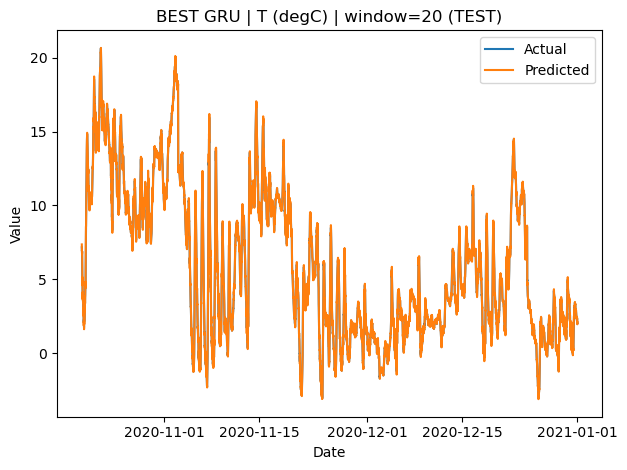


BEST → p (mbar) | GRU | window=10
{'MAE': 0.11704826, 'MSE': 0.025110425, 'RMSE': 0.15846269, 'R2': 0.999783396652573}


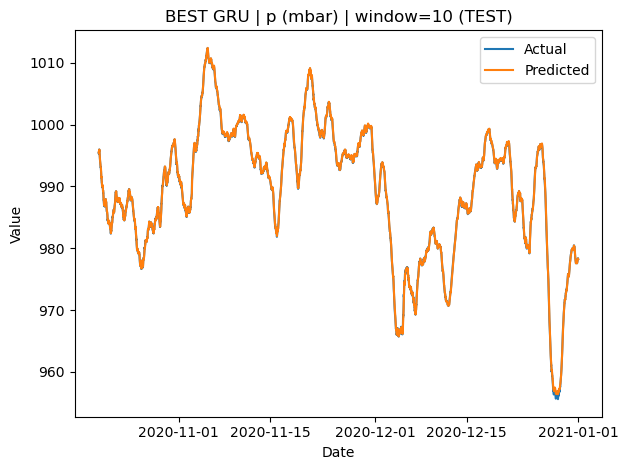


BEST → rh (%) | GRU | window=20
{'MAE': 0.746829, 'MSE': 1.3308969, 'RMSE': 1.153645, 'R2': 0.9900626921510091}


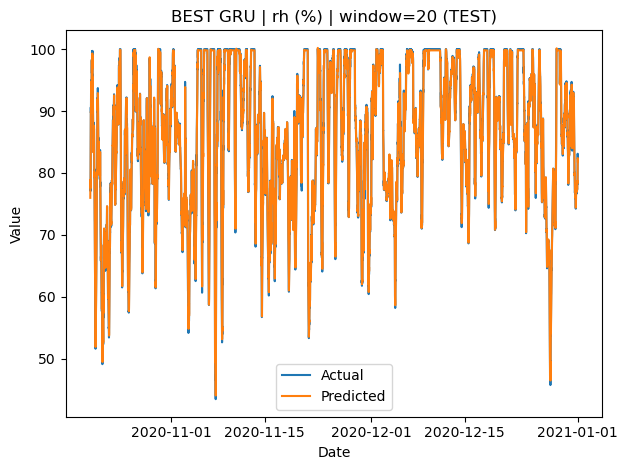

In [23]:
builders = {
    "LSTM": build_lstm,
    "GRU": build_gru,
    "CNN1D": build_cnn1d
}

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
]

for _, row in best_per_target.iterrows():
    target_col = row["target"]
    w = int(row["window"])
    model_name = row["model"]

    feature_cols = [target_col]

    Xtr, ytr, Xte, yte, t_te_idx = make_windows_all(
        scaled_df=all_scaled_df,
        split_idx=split_idx,
        feature_cols=feature_cols,
        target_col=target_col,
        window_size=w
    )

    model = builders[model_name]((Xtr.shape[1], Xtr.shape[2]))
    model.fit(
        Xtr, ytr,
        validation_split=0.1,
        epochs=30,
        batch_size=128,
        callbacks=callbacks,
        verbose=0
    )

    yhat_scaled = model.predict(Xte, verbose=0).reshape(-1)
    y_true = inverse_scale_target(yte, target_col)
    y_pred = inverse_scale_target(yhat_scaled, target_col)

    print(f"\nBEST → {target_col} | {model_name} | window={w}")
    print(evaluate_regression(y_true, y_pred))

    dates_test = data["date"].iloc[t_te_idx].values
    plot_actual_vs_pred(dates_test, y_true, y_pred,
                        f"BEST {model_name} | {target_col} | window={w} (TEST)")


In [25]:
best_T = (
    results_df[results_df["target"] == "T (degC)"]
      .sort_values("RMSE")
      .head(1)
      .reset_index(drop=True)
)
best_T


,target,mode,window,model,MAE,MSE,RMSE,R2
0,T (degC),univariate,20,GRU,0.121299,0.032866,0.181289,0.998679


## Multivariate : predict T using [T, p, rh] 

In [27]:

target_col = "T (degC)"
feature_cols = ["T (degC)", "p (mbar)", "rh (%)"]

best_window = int(best_T.loc[0, "window"])
print("Using best window for T:", best_window)

Xtr, ytr, Xte, yte, t_te_idx = make_windows_all(
    scaled_df=all_scaled_df,
    split_idx=split_idx,
    feature_cols=feature_cols,   # MULTIVARIATE INPUTS
    target_col=target_col,       # SINGLE TARGET
    window_size=best_window
)

input_shape = (Xtr.shape[1], Xtr.shape[2])
print("Xtr:", Xtr.shape, "Xte:", Xte.shape)

builders = {"LSTM": build_lstm, "GRU": build_gru, "CNN1D": build_cnn1d}
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
]

multi_results = []

for model_name in ["LSTM", "GRU", "CNN1D"]:
    model = builders[model_name](input_shape)

    model.fit(
        Xtr, ytr,
        validation_split=0.1,
        epochs=30,
        batch_size=128,
        callbacks=callbacks,
        verbose=0
    )

    yhat_scaled = model.predict(Xte, verbose=0).reshape(-1)

    y_true = inverse_scale_target(yte, target_col)
    y_pred = inverse_scale_target(yhat_scaled, target_col)

    metrics = evaluate_regression(y_true, y_pred)
    multi_results.append({
        "target": target_col,
        "mode": "multivariate",
        "window": best_window,
        "model": model_name,
        **metrics
    })

    print(f"MULTI {model_name} -> MAE={metrics['MAE']:.4f} | RMSE={metrics['RMSE']:.4f} | R2={metrics['R2']:.4f}")

multi_results_df = pd.DataFrame(multi_results).sort_values("RMSE").reset_index(drop=True)
multi_results_df


Using best window for T: 20
Xtr: (42136, 20, 3) Xte: (10540, 20, 3)
MULTI LSTM -> MAE=0.1269 | RMSE=0.1828 | R2=0.9987
MULTI GRU -> MAE=0.2037 | RMSE=0.2746 | R2=0.9970
MULTI CNN1D -> MAE=0.9502 | RMSE=1.2051 | R2=0.9416


,target,mode,window,model,MAE,MSE,RMSE,R2
0,T (degC),multivariate,20,LSTM,0.126853,0.033398,0.182751,0.998657
1,T (degC),multivariate,20,GRU,0.203715,0.075398,0.274587,0.996969
2,T (degC),multivariate,20,CNN1D,0.950193,1.452209,1.205076,0.941624


In [29]:
uni_best_T = (
    results_df[results_df["target"] == "T (degC)"]
      .sort_values("RMSE")
      .head(3)
      .reset_index(drop=True)
)

print("Top 3 UNIVARIATE for T:")
display(uni_best_T)

print("\nMULTIVARIATE for T (same window):")
display(multi_results_df)


Top 3 UNIVARIATE for T:


,target,mode,window,model,MAE,MSE,RMSE,R2
0,T (degC),univariate,20,GRU,0.121299,0.032866,0.181289,0.998679
1,T (degC),univariate,10,GRU,0.162311,0.053683,0.231695,0.997842
2,T (degC),univariate,30,GRU,0.162736,0.058763,0.242412,0.997638



MULTIVARIATE for T (same window):


,target,mode,window,model,MAE,MSE,RMSE,R2
0,T (degC),multivariate,20,LSTM,0.126853,0.033398,0.182751,0.998657
1,T (degC),multivariate,20,GRU,0.203715,0.075398,0.274587,0.996969
2,T (degC),multivariate,20,CNN1D,0.950193,1.452209,1.205076,0.941624


Best MULTI model: LSTM

FINAL MULTI METRICS:
{'MAE': 0.38059586, 'MSE': 0.28476033, 'RMSE': 0.5336294, 'R2': 0.988553243511744}

FINAL MULTI RESULTS TABLE:


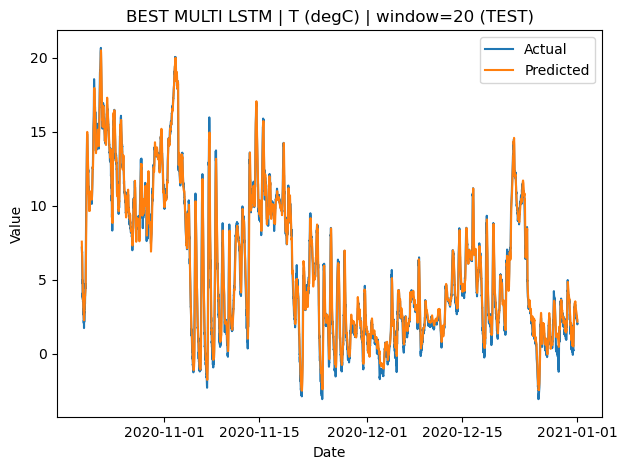

In [31]:
best_multi_model = multi_results_df.loc[0, "model"]
print("Best MULTI model:", best_multi_model)

model = builders[best_multi_model](input_shape)
model.fit(
    Xtr, ytr,
    validation_split=0.1,
    epochs=30,
    batch_size=128,
    callbacks=callbacks,
    verbose=0
)

yhat_scaled = model.predict(Xte, verbose=0).reshape(-1)
y_true = inverse_scale_target(yte, target_col)
y_pred = inverse_scale_target(yhat_scaled, target_col)

# --- FINAL METRICS (on REAL scale) ---
final_metrics = evaluate_regression(y_true, y_pred)
print("\nFINAL MULTI METRICS:")
print(final_metrics)

# store final metrics in a dict
final_multi_result = {
    "target": target_col,
    "mode": "multivariate_final",
    "window": best_window,
    "model": best_multi_model,
    **final_metrics
}

# convert to DataFrame for clean display
final_multi_df = pd.DataFrame([final_multi_result])
print("\nFINAL MULTI RESULTS TABLE:")
final_multi_df

dates_test = data["date"].iloc[t_te_idx].values
plot_actual_vs_pred(
    dates_test, y_true, y_pred,
    f"BEST MULTI {best_multi_model} | {target_col} | window={best_window} (TEST)"
)
